In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import entropy

MOVEMENT_DIR = Path(
    r"C:\Users\Sheel\OneDrive\Documents\Default Project\data\pads-parkinsons-disease-smartwatch-dataset-1.0.0\pads-parkinsons-disease-smartwatch-dataset-1.0.0\preprocessed\movement"
)

file_list = pd.read_csv(MOVEMENT_DIR.parent / "file_list.csv")

FS = 100.0

tasks = [
    "Relaxed1", "Relaxed2", "RelaxedTask1", "RelaxedTask2",
    "StretchHold", "HoldWeight", "DrinkGlas", "CrossArms",
    "TouchNose", "Entrainment1", "Entrainment2",
]
wrists = ["LeftWrist", "RightWrist"]
sensors = ["Accelerometer", "Gyroscope"]
axes = ["X", "Y", "Z"]
channels = [f"{t}_{w}_{s}_{a}" for t in tasks for w in wrists for s in sensors for a in axes]

print(len(channels), "channels")

132 channels


In [2]:
bin_files = sorted(MOVEMENT_DIR.glob("*_ml.bin"))
ids = np.array([int(f.name.split("_")[0]) for f in bin_files])
movement = np.stack([np.fromfile(f, dtype=np.float32).reshape(len(channels), -1) for f in bin_files])
print("movement:", movement.shape, movement.dtype)

movement: (469, 132, 976) float32


In [3]:
groups = {
    "Atypical Parkinsonism": [15, 18, 32, 64, 106, 110, 114, 118, 158, 168, 238, 280, 291, 304, 397],
    "Healthy": [46, 78, 81, 108, 148, 153, 160, 165, 214, 254, 295, 319, 335, 389, 463],
    "Essential Tremor": [66, 70, 72, 91, 112, 124, 143, 200, 275, 278, 302, 340, 350, 386, 396],
    "Parkinson's": [4, 95, 109, 113, 175, 206, 226, 249, 345, 347, 362, 365, 395, 406, 442],
}
id_to_group = {pid: g for g, pids in groups.items() for pid in pids}

demo = file_list.set_index("id").loc[sum(groups.values(), [])]
demo["group"] = [id_to_group[p] for p in demo.index]
summary = demo.groupby("group").agg(
    n=("age", "size"),
    male=("gender", lambda s: (s == "male").sum()),
    age_mean=("age", "mean"),
    age_std=("age", "std"),
)
print(summary.to_string())

                        n  male  age_mean   age_std
group                                              
Atypical Parkinsonism  15     8      66.0  7.964206
Essential Tremor       15     8      65.6  9.515401
Healthy                15     8      66.0  8.106435
Parkinson's            15     8      66.0  7.964206


In [4]:
mask = np.isin(ids, list(id_to_group))
mov = movement[mask]
pids = ids[mask]

channel_df = pd.DataFrame({
    "channel": channels,
    "task": [c.split("_")[0] for c in channels],
    "wrist": [c.split("_")[1] for c in channels],
    "sensor": [c.split("_")[2] for c in channels],
    "axis": [c.split("_")[3] for c in channels],
})

def stream_predictors(acc_norm):
    n = acc_norm.shape[1]
    freqs = np.fft.rfftfreq(n, d=1 / FS)
    dfreq = FS / n
    power = np.abs(np.fft.rfft(acc_norm, axis=1)) ** 2
    power_nn = power[:, 1:]
    primary_bin = np.argmax(power_nn, axis=1) + 1
    primary_freq = freqs[primary_bin]
    spec_entropy = entropy(power_nn, axis=1)
    jerk = np.diff(acc_norm, axis=1)
    tremor_band = ((freqs >= 3) & (freqs <= 8))[1:]
    rel_tremor_power = power_nn[:, tremor_band].sum(axis=1) / power_nn.sum(axis=1)
    harm_bins = np.stack([
        np.clip(np.round(k * freqs[primary_bin] / dfreq).astype(int), 0, len(freqs) - 1)
        for k in (2, 3)
    ], axis=1)
    rows = np.arange(power.shape[0])[:, None]
    harmonic_power = power[rows, harm_bins].sum(axis=1)
    main_power = power[np.arange(power.shape[0]), primary_bin]
    return {
        "Relative Tremor Power": rel_tremor_power,
        "Harmonic Power Ratio": harmonic_power / main_power,
        "Movement Amplitude": np.ptp(acc_norm, axis=1),
        "Acceleration Norm": acc_norm.mean(axis=1),
        "Jerk": jerk.mean(axis=1),
        "Spectral Entropy": spec_entropy,
        "Primary Frequency Component": primary_freq,
    }

predictor_names = [
    "Relative Tremor Power", "Harmonic Power Ratio", "Movement Amplitude",
    "Acceleration Norm", "Jerk", "Spectral Entropy", "Primary Frequency Component",
]
preds = {k: [] for k in predictor_names}
for (task, wrist), grp in channel_df.groupby(["task", "wrist"]):
    acc = mov[:, grp.index[grp["sensor"] == "Accelerometer"].tolist(), :]
    acc_norm = np.linalg.norm(acc, axis=1)
    stream = stream_predictors(acc_norm)
    for k in predictor_names:
        preds[k].append(stream[k])

df = pd.DataFrame({k: np.mean(v, axis=0) for k, v in preds.items()})
df["group"] = [id_to_group[p] for p in pids]
print(df.shape)
print(df.groupby("group").size())

(60, 8)
group
Atypical Parkinsonism    15
Essential Tremor         15
Healthy                  15
Parkinson's              15
dtype: int64


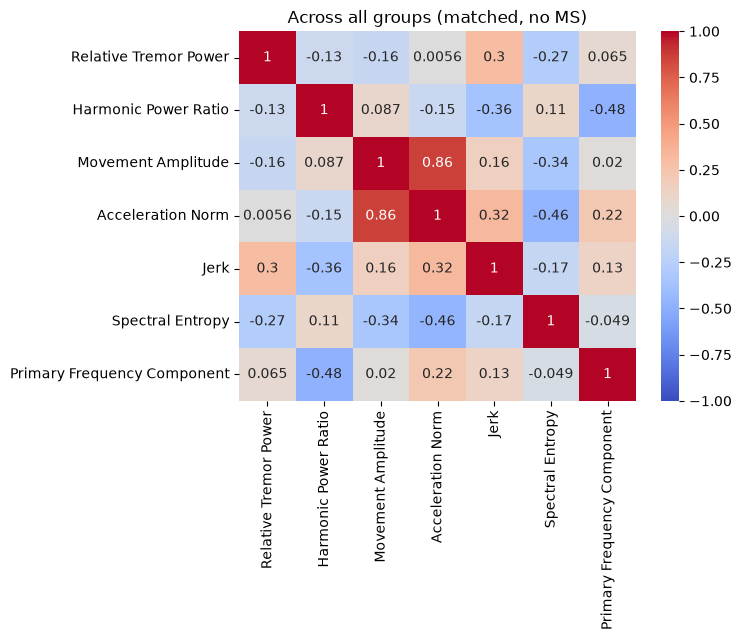

In [5]:
sns.heatmap(df.drop(columns=["group"]).corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Across all groups (matched, no MS)")
plt.show()

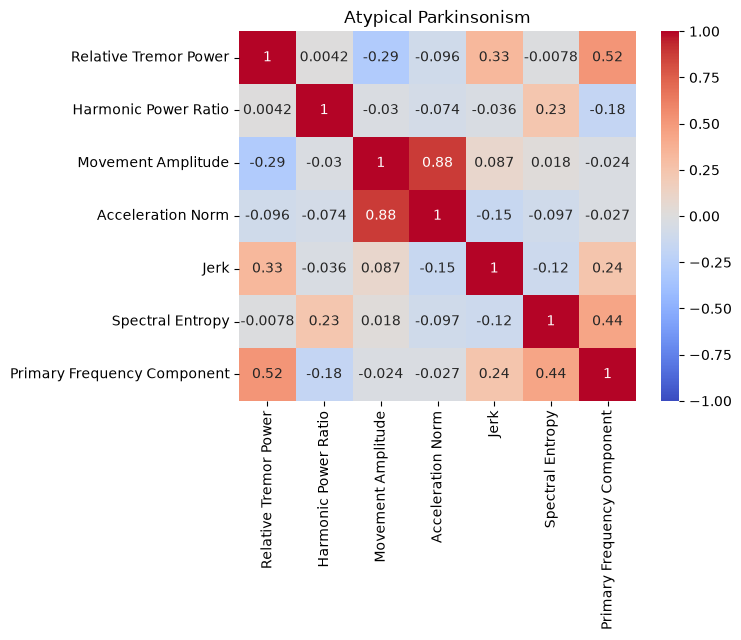

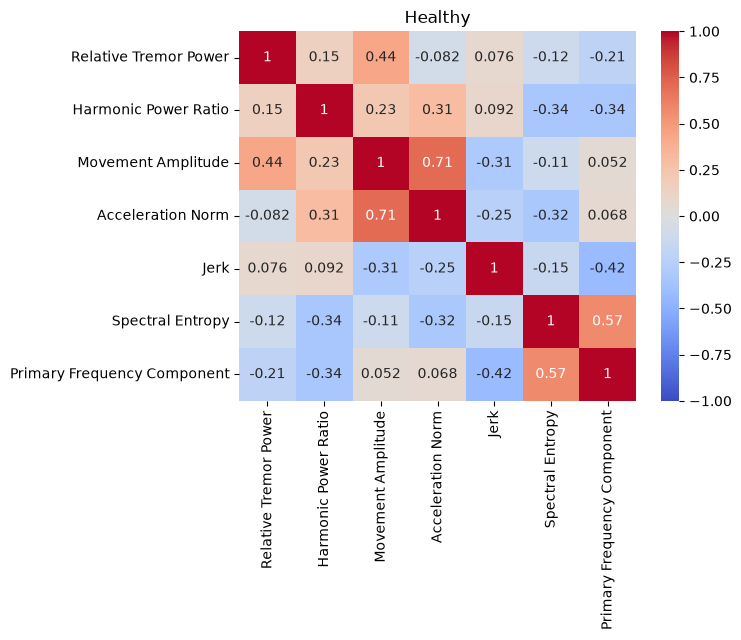

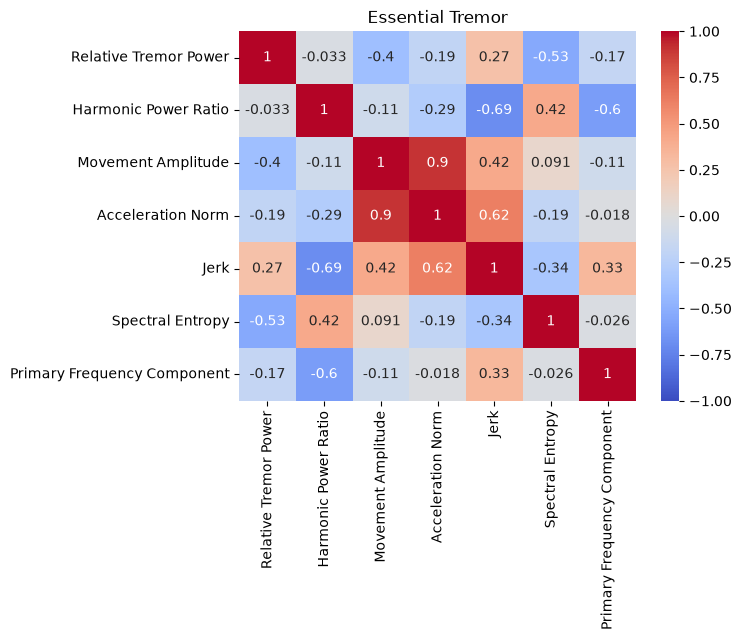

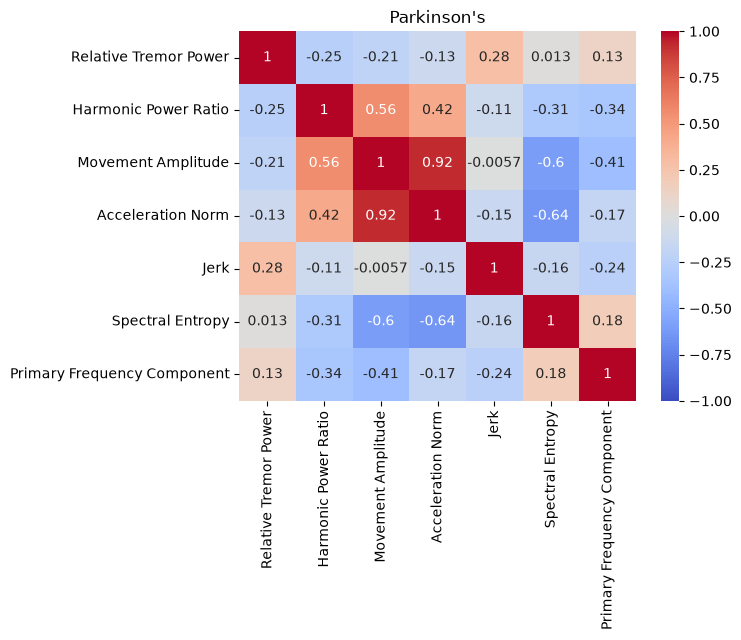

In [6]:
for g in groups:
    sub = df[df["group"] == g].drop(columns=["group"])
    sns.heatmap(sub.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
    plt.title(g)
    plt.show()